## DATASET ANALYSIS - CAPSTONE


## TILED IMAGES

In [4]:
from pathlib import Path
from collections import Counter

# CHANGE THIS PATH
DATASET_DIR = Path("/Users/aishwarya/Desktop/Capstone/BLOCKS_NORM_MACENKO/")

# Find patient folders
patient_folders = [
    folder for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
]

print("Number of patient folders:", len(patient_folders))

Number of patient folders: 100


In [5]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

patient_data = []

for patient_folder in sorted(patient_folders):

    images = [
        f for f in patient_folder.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    patient_data.append({
        "patient_id": patient_folder.name,
        "number_of_images": len(images)
    })

for row in patient_data:
    print(row["patient_id"], ":", row["number_of_images"], "images")

TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-8292-A9DBCA0BD37C : 100 images
TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FDD-6494E6EE2B71 : 100 images
TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-9007-F26B6F0682C4 : 100 images
TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D5-D8986E529B6C : 100 images
TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-9603-C7AC20C9DA1E : 100 images
TCGA-A2-A04U-01Z-00-DX1.06D17357-46A8-4DC3-A22B-2F4EB6EE3F79 : 100 images
TCGA-A2-A04V-01Z-00-DX1.EB430DDB-8FE9-4302-8829-53DBAD09E79F : 100 images
TCGA-A2-A04W-01Z-00-DX1.F7E7B945-2ADC-4741-8FCE-ACEA657DB9C7 : 100 images
TCGA-A2-A04X-01Z-00-DX1.E01A4522-67B3-4FEF-BD6B-99DFED9E7C85 : 100 images
TCGA-A2-A04Y-01Z-00-DX1.4DC97AD6-4806-4A3A-A998-FD36F93590A4 : 100 images
TCGA-A2-A0CK-01Z-00-DX1.C3226BD1-11B0-4034-946A-BAB42958CE85 : 100 images
TCGA-A2-A0CL-01Z-00-DX1.5342E971-DCD2-42C4-B4FF-E6942A95829E : 100 images
TCGA-A2-A0CM-01Z-00-DX1.AC4901DE-4B6D-4185-BB9F-156033839828 : 100 images
TCGA-A2-A0CO-01Z-00-DX1.B191DADE-7DEA-

In [7]:
import pandas as pd

df = pd.DataFrame(patient_data)

print("DATASET SUMMARY")
print("Number of patients:", len(df))
print("Total image tiles:", df["number_of_images"].sum())
print("Minimum tiles/patient:", df["number_of_images"].min())
print("Maximum tiles/patient:", df["number_of_images"].max())
print("Average tiles/patient:", df["number_of_images"].mean())

DATASET SUMMARY
Number of patients: 100
Total image tiles: 10000
Minimum tiles/patient: 100
Maximum tiles/patient: 100
Average tiles/patient: 100.0


In [8]:
from PIL import Image

first_patient = patient_folders[0]

first_image = next(
    f for f in first_patient.iterdir()
    if f.suffix.lower() in IMAGE_EXTENSIONS
)

img = Image.open(first_image)

print("Image:", first_image.name)
print("Size:", img.size)
print("Mode:", img.mode)

Image: TCGA-A2-A25A-01Z-00-DX1.6D311E39-9F96-4775-B9DA-8D034D1AD1DC_(16592,44591).jpg
Size: (256, 256)
Mode: RGB


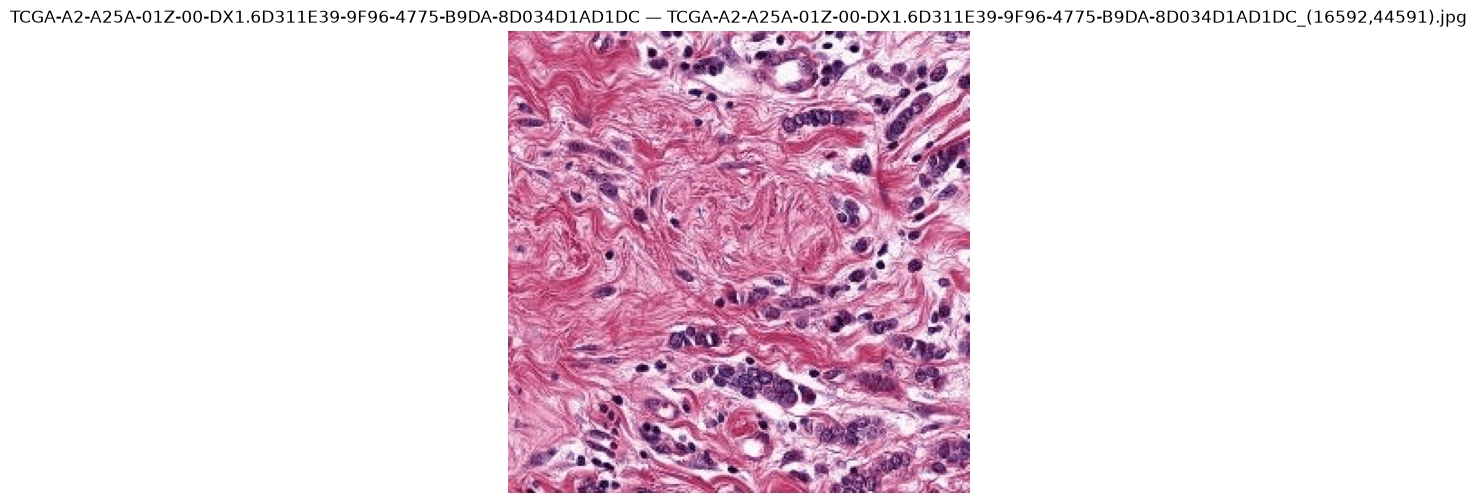

In [9]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_DIR = Path("/Users/aishwarya/Desktop/Capstone/BLOCKS_NORM_MACENKO/")

# Get first patient folder
patient_folder = next(folder for folder in DATASET_DIR.iterdir() if folder.is_dir())

# Get first image
image_file = next(
    f for f in patient_folder.iterdir()
    if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
)

# Open and display
img = Image.open(image_file)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"{patient_folder.name} — {image_file.name}")
plt.show()

## LABEL PROCESSING

In [1]:
import pandas as pd
import numpy as np

In [5]:
slide_path = "/Users/aishwarya/Desktop/Capstone/Dataset/TCGA-BRCA-A2_SLIDE.xlsx"
clini_path = "/Users/aishwarya/Desktop/Capstone/Dataset/TCGA-BRCA-A2-CLINI.xlsx"

slide_df = pd.read_excel(slide_path)
clini_df = pd.read_excel(clini_path)

## Slide Dataframe

In [6]:
print("SLIDE DATASET")
print("Shape:", slide_df.shape)
display(slide_df.head())

print("\nCLINICAL DATASET")
print("Shape:", clini_df.shape)
display(clini_df.head())

SLIDE DATASET
Shape: (100, 2)


,PATIENT,FILENAME
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...



CLINICAL DATASET
Shape: (102, 203)


,PATIENT,Sample ID,Diagnosis Age,American Joint Committee on Cancer Metastasis Stage Code,Neoplasm Disease Lymph Node Stage American Joint Committee on Cancer Code,Neoplasm Disease Stage American Joint Committee on Cancer Code,American Joint Committee on Cancer Publication Version Type,American Joint Committee on Cancer Tumor Stage Code,Brachytherapy first reference point administered total dose,Cancer Type,...,T Cells CD8,T Cells Follicular Helper,T Cells gamma delta,T Cells Regulatory Tregs,Lymphocytes,Neutrophils2,Eosinophils3,Mast Cells,Dendritic Cells,Macrophages
0,TCGA-A2-A04N,TCGA-A2-A04N-01,66,M0,N0 (i-),Stage IA,5th,T1c,NaN,Breast Cancer,...,0.073274,0.091463,0.0,0.000000,0.422387,0.001541,0.000000,0.143953,0.000000,0.432118
1,TCGA-A2-A04P,TCGA-A2-A04P-01,36,M0,N3c,Stage IIIC,6th,T2,NaN,Breast Cancer,...,0.082369,0.151754,0.0,0.085682,0.673064,0.000000,0.000581,0.027681,0.018148,0.280526
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01,48,M0,N0 (i-),Stage IA,6th,T1,NaN,Breast Cancer,...,0.164082,0.127177,0.0,0.056022,0.579036,0.000000,0.000000,0.016735,0.028523,0.375706
3,TCGA-A2-A04R,TCGA-A2-A04R-01,36,M0,N0 (i-),Stage IA,6th,T1,NaN,Breast Cancer,...,0.052870,0.021804,0.0,0.019850,0.188834,0.000000,0.000000,0.170607,0.000000,0.640558
4,TCGA-A2-A04T,TCGA-A2-A04T-01,62,M0,N0 (i-),Stage IIA,6th,T2,NaN,Breast Cancer,...,0.156457,0.113362,0.0,0.014260,0.664019,0.005852,0.000000,0.008820,0.014193,0.307117


In [7]:
slide_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   PATIENT   100 non-null    str  
 1   FILENAME  100 non-null    str  
dtypes: str(2)
memory usage: 1.7 KB


In [8]:
slide_df.describe(include="all").T

,count,unique,top,freq
PATIENT,100,100,TCGA-A2-A04N,1
FILENAME,100,100,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,1


In [9]:
print("Columns:")
for col in slide_df.columns:
    print(col)

Columns:
PATIENT
FILENAME


## Clinical Dataframe

In [11]:
clini_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Columns: 203 entries, PATIENT to Macrophages
dtypes: float64(112), int64(15), object(2), str(74)
memory usage: 161.9+ KB


In [12]:
print("Number of columns:", len(clini_df.columns))

for i, col in enumerate(clini_df.columns):
    print(i, ":", col)

Number of columns: 203
0 : PATIENT
1 : Sample ID
2 : Diagnosis Age
3 : American Joint Committee on Cancer Metastasis Stage Code
4 : Neoplasm Disease Lymph Node Stage American Joint Committee on Cancer Code
5 : Neoplasm Disease Stage American Joint Committee on Cancer Code
6 : American Joint Committee on Cancer Publication Version Type
7 : American Joint Committee on Cancer Tumor Stage Code
8 : Brachytherapy first reference point administered total dose
9 : Cancer Type
10 : Cancer Type Detailed
11 : Cent17 Copy Number
12 : Neoplasm American Joint Committee on Cancer Clinical Group Stage
13 : Neoplasm American Joint Committee on Cancer Clinical Distant Metastasis M Stage
14 : Neoplasm American Joint Committee on Cancer Clinical Regional Lymph Node N Stage
15 : Neoplasm American Joint Committee on Cancer Clinical Primary Tumor T Stage
16 : Days to Sample Collection.
17 : Last Alive Less Initial Pathologic Diagnosis Date Calculated Day Value
18 : days_to_patient_progression_free
19 : Days 

In [13]:
print("Clinical patients:", clini_df["PATIENT"].nunique())

display(
    clini_df[["PATIENT"]].head(10)
)

Clinical patients: 102


,PATIENT
0,TCGA-A2-A04N
1,TCGA-A2-A04P
2,TCGA-A2-A04Q
3,TCGA-A2-A04R
4,TCGA-A2-A04T
5,TCGA-A2-A04U
6,TCGA-A2-A04V
7,TCGA-A2-A04W
8,TCGA-A2-A04X
9,TCGA-A2-A04Y


In [14]:
slide_patients = set(slide_df["PATIENT"])
clini_patients = set(clini_df["PATIENT"])

print("Patients in slide dataset:", len(slide_patients))
print("Patients in clinical dataset:", len(clini_patients))

print("\nSlide patients missing from clinical:")
print(slide_patients - clini_patients)

print("\nClinical patients not in slide dataset:")
print(clini_patients - slide_patients)

Patients in slide dataset: 100
Patients in clinical dataset: 102

Slide patients missing from clinical:
set()

Clinical patients not in slide dataset:
{'TCGA-A2-A0D2', 'TCGA-A2-A0D1'}


## Merged Dataset

In [15]:
df = slide_df.merge(
    clini_df,
    on="PATIENT",
    how="left"
)

In [16]:
print("Shape:", df.shape)

Shape: (100, 204)


In [18]:
df.head()

,PATIENT,FILENAME,Sample ID,Diagnosis Age,American Joint Committee on Cancer Metastasis Stage Code,Neoplasm Disease Lymph Node Stage American Joint Committee on Cancer Code,Neoplasm Disease Stage American Joint Committee on Cancer Code,American Joint Committee on Cancer Publication Version Type,American Joint Committee on Cancer Tumor Stage Code,Brachytherapy first reference point administered total dose,...,T Cells CD8,T Cells Follicular Helper,T Cells gamma delta,T Cells Regulatory Tregs,Lymphocytes,Neutrophils2,Eosinophils3,Mast Cells,Dendritic Cells,Macrophages
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,TCGA-A2-A04N-01,66,M0,N0 (i-),Stage IA,5th,T1c,NaN,...,0.073274,0.091463,0.0,0.000000,0.422387,0.001541,0.000000,0.143953,0.000000,0.432118
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,TCGA-A2-A04P-01,36,M0,N3c,Stage IIIC,6th,T2,NaN,...,0.082369,0.151754,0.0,0.085682,0.673064,0.000000,0.000581,0.027681,0.018148,0.280526
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,TCGA-A2-A04Q-01,48,M0,N0 (i-),Stage IA,6th,T1,NaN,...,0.164082,0.127177,0.0,0.056022,0.579036,0.000000,0.000000,0.016735,0.028523,0.375706
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,TCGA-A2-A04R-01,36,M0,N0 (i-),Stage IA,6th,T1,NaN,...,0.052870,0.021804,0.0,0.019850,0.188834,0.000000,0.000000,0.170607,0.000000,0.640558
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,TCGA-A2-A04T-01,62,M0,N0 (i-),Stage IIA,6th,T2,NaN,...,0.156457,0.113362,0.0,0.014260,0.664019,0.005852,0.000000,0.008820,0.014193,0.307117


## Understand Updated Dataset

In [20]:
missing_summary = pd.DataFrame({
    "column": df.columns,
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "missing",
    ascending=False
)

display(missing_summary)

,column,missing,missing_%
Lymphomatous Extranodal Site Involvement Indicator,Lymphomatous Extranodal Site Involvement Indic...,100,100.0
HER2 positivity scale other,HER2 positivity scale other,100,100.0
Disease code,Disease code,100,100.0
Nte HER2 signal number,Nte HER2 signal number,100,100.0
Nte HER2 positivity other scale,Nte HER2 positivity other scale,100,100.0
...,...,...,...
Pathology Report File Name,Pathology Report File Name,0,0.0
Other Sample ID,Other Sample ID,0,0.0
Other Patient ID,Other Patient ID,0,0.0
Overall Survival Status,Overall Survival Status,0,0.0


## Biomarker Relevant Columns

In [21]:
er_cols = [
    col for col in df.columns
    if "ER" in col.upper()
]

er_cols

['American Joint Committee on Cancer Metastasis Stage Code',
 'Neoplasm Disease Lymph Node Stage American Joint Committee on Cancer Code',
 'Neoplasm Disease Stage American Joint Committee on Cancer Code',
 'American Joint Committee on Cancer Publication Version Type',
 'American Joint Committee on Cancer Tumor Stage Code',
 'Brachytherapy first reference point administered total dose',
 'Cancer Type',
 'Cancer Type Detailed',
 'Cent17 Copy Number',
 'Neoplasm American Joint Committee on Cancer Clinical Group Stage',
 'Neoplasm American Joint Committee on Cancer Clinical Distant Metastasis M Stage',
 'Neoplasm American Joint Committee on Cancer Clinical Regional Lymph Node N Stage',
 'Neoplasm American Joint Committee on Cancer Clinical Primary Tumor T Stage',
 'ER positivity scale other',
 'ER positivity scale used',
 'ER Status By IHC',
 'ER Status IHC Percent Positive',
 'First surgical procedure other',
 'Fraction Genome Altered',
 'HER2 and cent17 cells count',
 'HER2 and cent17 s

In [22]:
pr_cols = [
    col for col in df.columns
    if "PR" in col.upper()
]

pr_cols

['Neoplasm American Joint Committee on Cancer Clinical Primary Tumor T Stage',
 'days_to_patient_progression_free',
 'Days to Sample Procurement',
 'days_to_tumor_progression',
 'First surgical procedure other',
 'Neoadjuvant Therapy Type Administered Prior To Resection Text',
 'Prior Cancer Diagnosis Occurence',
 'Primary Lymph Node Presentation Assessment Ind-3',
 'Nte pr ihc intensity score',
 'Nte pr positivity define method',
 'Nte pr positivity other scale',
 'Nte pr status by ihc',
 'Nte pr status ihc positive',
 'Primary Other Site of Disease Name',
 'Patient Primary Tumor Site',
 'Project code',
 'Tissue Prospective Collection Indicator',
 'PR positivity define method',
 'PR positivity ihc intensity score',
 'PR positivity scale other',
 'PR positivity scale used',
 'PR status by ihc',
 'PR status ihc percent positive',
 'Surgical procedure first',
 'Proliferation']

In [23]:
her2_cols = [
    col for col in df.columns
    if "HER2" in col.upper()
]

her2_cols

['HER2 and cent17 cells count',
 'HER2 and cent17 scale other',
 'HER2 cent17 counted cells count',
 'HER2 cent17 ratio',
 'HER2 copy number',
 'HER2 fish method',
 'HER2 fish status',
 'HER2 ihc percent positive',
 'HER2 ihc score',
 'HER2 positivity method text',
 'HER2 positivity scale other',
 'IHC-HER2',
 'Nte cent17 HER2 other scale',
 'Nte cent 17 HER2 ratio',
 'Nte HER2 fish define method',
 'Nte HER2 fish status',
 'Nte HER2 positivity ihc score',
 'Nte HER2 positivity method',
 'Nte HER2 positivity other scale',
 'Nte HER2 signal number',
 'Nte HER2 status',
 'Nte HER2 status ihc positive']

## Preprocessed Dataset with Relevant Columns

In [25]:
mapping_cols = [
    "PATIENT",
    "Sample ID"
]

er_keep = [
    "ER Status By IHC",
    "ER Status IHC Percent Positive",
    "ER positivity scale used",
    "ER positivity scale other"
]

pr_keep = [
    "PR status by ihc",
    "PR status ihc percent positive",
    "PR positivity define method",
    "PR positivity ihc intensity score",
    "PR positivity scale used",
    "PR positivity scale other"
]

her2_keep = [
    "HER2 and cent17 cells count",
    "HER2 and cent17 scale other",
    "HER2 cent17 counted cells count",
    "HER2 cent17 ratio",
    "HER2 copy number",
    "HER2 fish method",
    "HER2 fish status",
    "HER2 ihc percent positive",
    "HER2 ihc score",
    "HER2 positivity method text",
    "HER2 positivity scale other",
    "IHC-HER2",
    "IHC Score"
]

keep_cols = mapping_cols + er_keep + pr_keep + her2_keep

final_df = df[keep_cols].copy()

In [27]:
print("Original dataframe:", df.shape)
print("Working dataframe:", final_df.shape)

display(final_df.head())

Original dataframe: (100, 204)
Working dataframe: (100, 25)


,PATIENT,Sample ID,ER Status By IHC,ER Status IHC Percent Positive,ER positivity scale used,ER positivity scale other,PR status by ihc,PR status ihc percent positive,PR positivity define method,PR positivity ihc intensity score,...,HER2 cent17 ratio,HER2 copy number,HER2 fish method,HER2 fish status,HER2 ihc percent positive,HER2 ihc score,HER2 positivity method text,HER2 positivity scale other,IHC-HER2,IHC Score
0,TCGA-A2-A04N,TCGA-A2-A04N-01,Positive,NaN,NaN,NaN,Positive,NaN,NaN,NaN,...,1.2,NaN,NaN,Negative,NaN,NaN,NaN,NaN,NaN,NaN
1,TCGA-A2-A04P,TCGA-A2-A04P-01,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,1.3,NaN,NaN,Negative,NaN,NaN,NaN,NaN,NaN,NaN
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,1.4,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN
3,TCGA-A2-A04R,TCGA-A2-A04R-01,Positive,60-69%,NaN,NaN,Positive,80-89%,NaN,NaN,...,1.1,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN
4,TCGA-A2-A04T,TCGA-A2-A04T-01,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,1.1,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN


In [28]:
final_df = slide_df.merge(
    clini_df[["PATIENT"] + er_keep + pr_keep + her2_keep + ["Sample ID"]],
    on="PATIENT",
    how="left",
    validate="one_to_one"
)

In [30]:
print(final_df.shape)
display(final_df.head())

(100, 26)


,PATIENT,FILENAME,ER Status By IHC,ER Status IHC Percent Positive,ER positivity scale used,ER positivity scale other,PR status by ihc,PR status ihc percent positive,PR positivity define method,PR positivity ihc intensity score,...,HER2 copy number,HER2 fish method,HER2 fish status,HER2 ihc percent positive,HER2 ihc score,HER2 positivity method text,HER2 positivity scale other,IHC-HER2,IHC Score,Sample ID
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Positive,NaN,NaN,NaN,Positive,NaN,NaN,NaN,...,NaN,NaN,Negative,NaN,NaN,NaN,NaN,NaN,NaN,TCGA-A2-A04N-01
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,NaN,NaN,Negative,NaN,NaN,NaN,NaN,NaN,NaN,TCGA-A2-A04P-01
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN,TCGA-A2-A04Q-01
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Positive,60-69%,NaN,NaN,Positive,80-89%,NaN,NaN,...,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN,TCGA-A2-A04R-01
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,<10%,NaN,NaN,Negative,<10%,NaN,NaN,...,NaN,NaN,Negative,NaN,2.0,NaN,NaN,Equivocal,NaN,TCGA-A2-A04T-01


In [31]:
print("Number of columns:", len(working_df.columns))

for i, col in enumerate(working_df.columns):
    print(i, ":", col)

Number of columns: 25
0 : PATIENT
1 : Sample ID
2 : ER Status By IHC
3 : ER Status IHC Percent Positive
4 : ER positivity scale used
5 : ER positivity scale other
6 : PR status by ihc
7 : PR status ihc percent positive
8 : PR positivity define method
9 : PR positivity ihc intensity score
10 : PR positivity scale used
11 : PR positivity scale other
12 : HER2 and cent17 cells count
13 : HER2 and cent17 scale other
14 : HER2 cent17 counted cells count
15 : HER2 cent17 ratio
16 : HER2 copy number
17 : HER2 fish method
18 : HER2 fish status
19 : HER2 ihc percent positive
20 : HER2 ihc score
21 : HER2 positivity method text
22 : HER2 positivity scale other
23 : IHC-HER2
24 : IHC Score


In [32]:
print("ER Status:")
print(
    final_df["ER Status By IHC"]
    .value_counts(dropna=False)
)

print("\nER % Positive:")
print(
    working_df["ER Status IHC Percent Positive"]
    .value_counts(dropna=False)
)

ER Status:
ER Status By IHC
Positive    76
Negative    24
Name: count, dtype: int64

ER % Positive:
ER Status IHC Percent Positive
90-99%    47
<10%      18
NaN       16
80-89%     7
60-69%     5
40-49%     3
70-79%     3
20-29%     1
Name: count, dtype: int64


In [33]:
pd.crosstab(
    final_df["ER Status By IHC"],
    final_df["ER Status IHC Percent Positive"],
    dropna=False
)

ER Status IHC Percent Positive,20-29%,40-49%,60-69%,70-79%,80-89%,90-99%,<10%,NaN
ER Status By IHC,,,,,,,,
Negative,0,0,0,0,0,0,13,11
Positive,1,3,5,3,7,47,5,5


In [34]:
print("PR Status:")
print(
    working_df["PR status by ihc"]
    .value_counts(dropna=False)
)

print("\nPR % Positive:")
print(
    working_df["PR status ihc percent positive"]
    .value_counts(dropna=False)
)

PR Status:
PR status by ihc
Positive    62
Negative    38
Name: count, dtype: int64

PR % Positive:
PR status ihc percent positive
<10%      29
90-99%    21
NaN       20
10-19%     9
80-89%     7
70-79%     4
60-69%     4
20-29%     3
50-59%     2
40-49%     1
Name: count, dtype: int64


In [35]:
pd.crosstab(
    final_df["PR status by ihc"],
    final_df["PR status ihc percent positive"],
    dropna=False
)

PR status ihc percent positive,10-19%,20-29%,40-49%,50-59%,60-69%,70-79%,80-89%,90-99%,<10%,NaN
PR status by ihc,,,,,,,,,,
Negative,0,0,0,0,0,0,0,0,21,17
Positive,9,3,1,2,4,4,7,21,8,3


In [36]:
her2_check_cols = [
    "HER2 fish status",
    "HER2 ihc score",
    "HER2 ihc percent positive",
    "IHC-HER2",
    "IHC Score",
    "HER2 cent17 ratio",
    "HER2 copy number"
]

for col in her2_check_cols:
    print("\n==============================")
    print(col)
    print(working_df[col].value_counts(dropna=False))


HER2 fish status
HER2 fish status
Negative     60
NaN          32
Positive      7
Equivocal     1
Name: count, dtype: int64

HER2 ihc score
HER2 ihc score
1.0    31
NaN    29
2.0    22
0.0    11
3.0     7
Name: count, dtype: int64

HER2 ihc percent positive
HER2 ihc percent positive
NaN     92
<10%     8
Name: count, dtype: int64

IHC-HER2
IHC-HER2
Negative     56
Equivocal    22
NaN          14
Positive      8
Name: count, dtype: int64

IHC Score
IHC Score
NaN    68
3.0    18
2.0     6
1.0     5
0.0     3
Name: count, dtype: int64

HER2 cent17 ratio
HER2 cent17 ratio
NaN      33
1.10     14
1.30     10
1.20      5
1.40      4
1.00      4
1.13      3
3.20      2
1.22      2
2.20      1
0.50      1
0.89      1
1.17      1
1.41      1
1.14      1
1.60      1
1.32      1
1.09      1
0.97      1
1.33      1
7.00      1
4.80      1
1.18      1
1.04      1
1.08      1
0.92      1
16.30     1
0.93      1
2.10      1
2.60      1
1.31      1
1.25      1
Name: count, dtype: int64

HER2 copy num

## After Analysis, Final Df

In [37]:
keep_cols = [
    # Image / patient mapping
    "PATIENT",
    "FILENAME",

    # ER
    "ER Status By IHC",
    "ER Status IHC Percent Positive",

    # PR
    "PR status by ihc",
    "PR status ihc percent positive",

    # HER2
    "HER2 fish status",
    "HER2 ihc score",
    "IHC-HER2",
    "IHC Score",
    "HER2 cent17 ratio"
]

In [38]:
final_df = df[keep_cols].copy()

In [39]:
print(final_df.shape)
display(final_df.head())

(100, 11)


,PATIENT,FILENAME,ER Status By IHC,ER Status IHC Percent Positive,PR status by ihc,PR status ihc percent positive,HER2 fish status,HER2 ihc score,IHC-HER2,IHC Score,HER2 cent17 ratio
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Positive,NaN,Positive,NaN,Negative,NaN,NaN,NaN,1.2
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,<10%,Negative,<10%,Negative,NaN,NaN,NaN,1.3
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,<10%,Negative,<10%,Negative,2.0,Equivocal,NaN,1.4
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Positive,60-69%,Positive,80-89%,Negative,2.0,Equivocal,NaN,1.1
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,<10%,Negative,<10%,Negative,2.0,Equivocal,NaN,1.1


## NaN Values

In [40]:
final_df.isna().sum()

PATIENT                            0
FILENAME                           0
ER Status By IHC                   0
ER Status IHC Percent Positive    16
PR status by ihc                   0
PR status ihc percent positive    20
HER2 fish status                  32
HER2 ihc score                    29
IHC-HER2                          14
IHC Score                         68
HER2 cent17 ratio                 33
dtype: int64

In [41]:
missing_summary = pd.DataFrame({
    "Column": final_df.columns,
    "Missing": final_df.isna().sum(),
    "Missing_%": (final_df.isna().mean() * 100).round(2)
})

display(missing_summary)

,Column,Missing,Missing_%
PATIENT,PATIENT,0,0.0
FILENAME,FILENAME,0,0.0
ER Status By IHC,ER Status By IHC,0,0.0
ER Status IHC Percent Positive,ER Status IHC Percent Positive,16,16.0
PR status by ihc,PR status by ihc,0,0.0
PR status ihc percent positive,PR status ihc percent positive,20,20.0
HER2 fish status,HER2 fish status,32,32.0
HER2 ihc score,HER2 ihc score,29,29.0
IHC-HER2,IHC-HER2,14,14.0
IHC Score,IHC Score,68,68.0


In [43]:
er_percent_nan = final_df[
    final_df["ER Status IHC Percent Positive"].isna()
]

print("Number of ER % missing:", len(er_percent_nan))

display(
    er_percent_nan[
        [
            "PATIENT",
            "ER Status By IHC",
            "ER Status IHC Percent Positive"
        ]
    ]
)

Number of ER % missing: 16


,PATIENT,ER Status By IHC,ER Status IHC Percent Positive
0,TCGA-A2-A04N,Positive,NaN
22,TCGA-A2-A0CX,Positive,NaN
28,TCGA-A2-A0EM,Positive,NaN
29,TCGA-A2-A0EN,Positive,NaN
30,TCGA-A2-A0EO,Positive,NaN
41,TCGA-A2-A0ST,Negative,NaN
45,TCGA-A2-A0SX,Negative,NaN
72,TCGA-A2-A1G1,Negative,NaN
74,TCGA-A2-A1G6,Negative,NaN
81,TCGA-A2-A25F,Negative,NaN


In [44]:
pr_percent_nan = final_df[
    final_df["PR status ihc percent positive"].isna()
]

print("Number of PR % missing:", len(pr_percent_nan))

display(
    pr_percent_nan[
        [
            "PATIENT",
            "PR status by ihc",
            "PR status ihc percent positive"
        ]
    ]
)

Number of PR % missing: 20


,PATIENT,PR status by ihc,PR status ihc percent positive
0,TCGA-A2-A04N,Positive,NaN
28,TCGA-A2-A0EM,Positive,NaN
30,TCGA-A2-A0EO,Positive,NaN
31,TCGA-A2-A0EP,Negative,NaN
41,TCGA-A2-A0ST,Negative,NaN
45,TCGA-A2-A0SX,Negative,NaN
68,TCGA-A2-A1FW,Negative,NaN
72,TCGA-A2-A1G1,Negative,NaN
74,TCGA-A2-A1G6,Negative,NaN
79,TCGA-A2-A25D,Negative,NaN


In [45]:
her2_cols = [
    "HER2 fish status",
    "HER2 ihc score",
    "IHC-HER2",
    "IHC Score",
    "HER2 cent17 ratio"
]

her2_nan = final_df[
    final_df[her2_cols].isna().any(axis=1)
]

print("Patients with at least one HER2 NaN:", len(her2_nan))

display(
    her2_nan[
        ["PATIENT", "FILENAME"] + her2_cols
    ]
)

Patients with at least one HER2 NaN: 93


,PATIENT,FILENAME,HER2 fish status,HER2 ihc score,IHC-HER2,IHC Score,HER2 cent17 ratio
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Negative,NaN,NaN,NaN,1.2
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,NaN,NaN,NaN,1.3
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,2.0,Equivocal,NaN,1.4
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Negative,2.0,Equivocal,NaN,1.1
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,2.0,Equivocal,NaN,1.1
...,...,...,...,...,...,...,...
95,TCGA-A2-A4RY,TCGA-A2-A4RY-01Z-00-DX1.143E32FC-E10F-4590-9C7...,NaN,1.0,Negative,2.0,NaN
96,TCGA-A2-A4S0,TCGA-A2-A4S0-01Z-00-DX1.5878187D-325F-4274-BE4...,NaN,1.0,Negative,3.0,NaN
97,TCGA-A2-A4S1,TCGA-A2-A4S1-01Z-00-DX1.C69B14F6-5021-4FD8-8F2...,NaN,NaN,Negative,1.0,NaN
98,TCGA-A2-A4S2,TCGA-A2-A4S2-01Z-00-DX1.D779B63B-8817-43F1-A8F...,NaN,1.0,Negative,2.0,NaN


In [46]:
pd.crosstab(
    final_df["HER2 ihc score"],
    final_df["IHC Score"],
    dropna=False
)

IHC Score,0.0,1.0,2.0,3.0,NaN
HER2 ihc score,,,,,
0.0,2,1,0,2,6
1.0,0,1,3,8,19
2.0,0,1,0,4,17
3.0,1,0,0,1,5
NaN,0,2,3,3,21


In [47]:
pd.crosstab(
    final_df["HER2 ihc score"],
    final_df["IHC-HER2"],
    dropna=False
)

IHC-HER2,Equivocal,Negative,Positive,NaN
HER2 ihc score,,,,
0.0,0,11,0,0
1.0,0,31,0,0
2.0,22,0,0,0
3.0,0,0,7,0
NaN,0,14,1,14


In [48]:
pd.crosstab(
    final_df["HER2 ihc score"],
    final_df["HER2 fish status"],
    dropna=False
)

HER2 fish status,Equivocal,Negative,Positive,NaN
HER2 ihc score,,,,
0.0,0,4,0,7
1.0,0,15,1,15
2.0,1,19,2,0
3.0,0,1,2,4
NaN,0,21,2,6


In [49]:
# 1
display(er_percent_nan[["PATIENT", "ER Status By IHC",
                        "ER Status IHC Percent Positive"]])

# 2
display(pr_percent_nan[["PATIENT", "PR status by ihc",
                        "PR status ihc percent positive"]])

# 3
display(her2_nan[["PATIENT", "FILENAME"] + her2_cols])

# 4
display(pd.crosstab(
    final_df["HER2 ihc score"],
    final_df["IHC-HER2"],
    dropna=False
))

,PATIENT,ER Status By IHC,ER Status IHC Percent Positive
0,TCGA-A2-A04N,Positive,NaN
22,TCGA-A2-A0CX,Positive,NaN
28,TCGA-A2-A0EM,Positive,NaN
29,TCGA-A2-A0EN,Positive,NaN
30,TCGA-A2-A0EO,Positive,NaN
41,TCGA-A2-A0ST,Negative,NaN
45,TCGA-A2-A0SX,Negative,NaN
72,TCGA-A2-A1G1,Negative,NaN
74,TCGA-A2-A1G6,Negative,NaN
81,TCGA-A2-A25F,Negative,NaN


,PATIENT,PR status by ihc,PR status ihc percent positive
0,TCGA-A2-A04N,Positive,NaN
28,TCGA-A2-A0EM,Positive,NaN
30,TCGA-A2-A0EO,Positive,NaN
31,TCGA-A2-A0EP,Negative,NaN
41,TCGA-A2-A0ST,Negative,NaN
45,TCGA-A2-A0SX,Negative,NaN
68,TCGA-A2-A1FW,Negative,NaN
72,TCGA-A2-A1G1,Negative,NaN
74,TCGA-A2-A1G6,Negative,NaN
79,TCGA-A2-A25D,Negative,NaN


,PATIENT,FILENAME,HER2 fish status,HER2 ihc score,IHC-HER2,IHC Score,HER2 cent17 ratio
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Negative,NaN,NaN,NaN,1.2
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,NaN,NaN,NaN,1.3
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,2.0,Equivocal,NaN,1.4
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Negative,2.0,Equivocal,NaN,1.1
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,2.0,Equivocal,NaN,1.1
...,...,...,...,...,...,...,...
95,TCGA-A2-A4RY,TCGA-A2-A4RY-01Z-00-DX1.143E32FC-E10F-4590-9C7...,NaN,1.0,Negative,2.0,NaN
96,TCGA-A2-A4S0,TCGA-A2-A4S0-01Z-00-DX1.5878187D-325F-4274-BE4...,NaN,1.0,Negative,3.0,NaN
97,TCGA-A2-A4S1,TCGA-A2-A4S1-01Z-00-DX1.C69B14F6-5021-4FD8-8F2...,NaN,NaN,Negative,1.0,NaN
98,TCGA-A2-A4S2,TCGA-A2-A4S2-01Z-00-DX1.D779B63B-8817-43F1-A8F...,NaN,1.0,Negative,2.0,NaN


IHC-HER2,Equivocal,Negative,Positive,NaN
HER2 ihc score,,,,
0.0,0,11,0,0
1.0,0,31,0,0
2.0,22,0,0,0
3.0,0,0,7,0
NaN,0,14,1,14


In [50]:
keep_cols = [
    "PATIENT",
    "FILENAME",

    # ER
    "ER Status By IHC",

    # PR
    "PR status by ihc",

    # HER2
    "HER2 fish status",
    "HER2 ihc score",
    "IHC-HER2",
    "HER2 cent17 ratio"
]

final_df = df[keep_cols].copy()

print(final_df.shape)
display(final_df.head())

(100, 8)


,PATIENT,FILENAME,ER Status By IHC,PR status by ihc,HER2 fish status,HER2 ihc score,IHC-HER2,HER2 cent17 ratio
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Positive,Positive,Negative,NaN,NaN,1.2
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,Negative,Negative,NaN,NaN,1.3
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,Negative,Negative,2.0,Equivocal,1.4
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Positive,Positive,Negative,2.0,Equivocal,1.1
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,Negative,Negative,2.0,Equivocal,1.1


In [51]:
pd.crosstab(
    final_df["IHC-HER2"],
    final_df["HER2 fish status"],
    dropna=False
)

HER2 fish status,Equivocal,Negative,Positive,NaN
IHC-HER2,,,,
Equivocal,1,19,2,0
Negative,0,27,1,28
Positive,0,1,3,4
NaN,0,13,1,0


In [52]:
pd.crosstab(
    final_df["HER2 ihc score"],
    final_df["HER2 fish status"],
    dropna=False
)

HER2 fish status,Equivocal,Negative,Positive,NaN
HER2 ihc score,,,,
0.0,0,4,0,7
1.0,0,15,1,15
2.0,1,19,2,0
3.0,0,1,2,4
NaN,0,21,2,6


In [53]:
her2_equivocal = final_df[
    final_df["IHC-HER2"] == "Equivocal"
]

print("IHC-HER2 equivocal patients:", len(her2_equivocal))

display(
    her2_equivocal[
        [
            "PATIENT",
            "HER2 ihc score",
            "IHC-HER2",
            "HER2 fish status",
            "HER2 cent17 ratio"
        ]
    ]
)

IHC-HER2 equivocal patients: 22


,PATIENT,HER2 ihc score,IHC-HER2,HER2 fish status,HER2 cent17 ratio
2,TCGA-A2-A04Q,2.0,Equivocal,Negative,1.40
3,TCGA-A2-A04R,2.0,Equivocal,Negative,1.10
4,TCGA-A2-A04T,2.0,Equivocal,Negative,1.10
6,TCGA-A2-A04V,2.0,Equivocal,Negative,1.10
15,TCGA-A2-A0CQ,2.0,Equivocal,Negative,1.30
17,TCGA-A2-A0CS,2.0,Equivocal,Negative,1.30
18,TCGA-A2-A0CT,2.0,Equivocal,Negative,1.30
19,TCGA-A2-A0CU,2.0,Equivocal,Negative,1.00
21,TCGA-A2-A0CW,2.0,Equivocal,Negative,0.50
29,TCGA-A2-A0EN,2.0,Equivocal,Negative,1.40


In [54]:
her2_fish_positive = final_df[
    final_df["HER2 fish status"] == "Positive"
]

display(
    her2_fish_positive[
        [
            "PATIENT",
            "HER2 ihc score",
            "IHC-HER2",
            "HER2 fish status",
            "HER2 cent17 ratio"
        ]
    ]
)

,PATIENT,HER2 ihc score,IHC-HER2,HER2 fish status,HER2 cent17 ratio
5,TCGA-A2-A04U,1.0,Negative,Positive,2.2
7,TCGA-A2-A04W,NaN,Positive,Positive,3.2
8,TCGA-A2-A04X,3.0,Positive,Positive,3.2
40,TCGA-A2-A0EY,3.0,Positive,Positive,7.0
46,TCGA-A2-A0SY,NaN,NaN,Positive,4.8
72,TCGA-A2-A1G1,2.0,Equivocal,Positive,16.3
87,TCGA-A2-A3XV,2.0,Equivocal,Positive,2.6


## Final Df

In [55]:
keep_cols = [
    "PATIENT",
    "FILENAME",

    # ER
    "ER Status By IHC",

    # PR
    "PR status by ihc",

    # HER2
    "HER2 ihc score",
    "HER2 fish status",
    "HER2 cent17 ratio"
]

final_df = df[keep_cols].copy()

print(final_df.shape)
display(final_df.head())

(100, 7)


,PATIENT,FILENAME,ER Status By IHC,PR status by ihc,HER2 ihc score,HER2 fish status,HER2 cent17 ratio
0,TCGA-A2-A04N,TCGA-A2-A04N-01Z-00-DX1.9E9B7DB0-1CF1-4631-829...,Positive,Positive,NaN,Negative,1.2
1,TCGA-A2-A04P,TCGA-A2-A04P-01Z-00-DX1.5B481E02-D269-4732-8FD...,Negative,Negative,NaN,Negative,1.3
2,TCGA-A2-A04Q,TCGA-A2-A04Q-01Z-00-DX1.DF7ED6B6-7701-486D-900...,Negative,Negative,2.0,Negative,1.4
3,TCGA-A2-A04R,TCGA-A2-A04R-01Z-00-DX1.BE3661A3-A2A0-4248-B7D...,Positive,Positive,2.0,Negative,1.1
4,TCGA-A2-A04T,TCGA-A2-A04T-01Z-00-DX1.71444266-BD56-4183-960...,Negative,Negative,2.0,Negative,1.1
